#### Requirements

In [13]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal
from src.summary import summary

In [14]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [15]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

#### Cyclic-Shifting Exploration

In [16]:
x = np.random.choice(np.arange(lookback + 1, len(momentum_position)), replace = False)

group_1 = []
group_2 = []

for i in range(lookback + 1, len(momentum_position)):

    if i < x:
        group_1.append(momentum_position.iloc[i])
    elif i >= x:
        group_2.append(momentum_position.iloc[i])

In [17]:
sequence = []

sequence.extend(group_2)
sequence.extend(group_1)

sequence.append(np.nan)
random_signal = ([np.nan] * lookback) + sequence

sequence


[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float6

In [18]:
random_df, random_result = backtester(returns, random_signal, 0.001)
random_df.iloc[250:260]

,return,signal,position,strategy_return,transaction_cost,net_strategy_return,equity,running_peak,drawdown
250,0.003047,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
251,-0.018929,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
252,-0.018104,0.0,NaN,NaN,0.0,NaN,1.0,1.0,0.0
253,0.048035,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
254,-0.010764,0.0,0.0,-0.0,0.0,-0.0,1.0,1.0,0.0
255,-0.032643,0.0,0.0,-0.0,0.0,-0.0,1.0,1.0,0.0
256,0.007741,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
257,-0.002641,0.0,0.0,-0.0,0.0,-0.0,1.0,1.0,0.0
258,0.017570,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
259,0.000946,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [19]:
one_count = 0
zero_count = 0

for i in range(len(sequence)):
    if sequence[i] == 1:
        one_count += 1
    elif sequence[i] == 0:
        zero_count += 1

print(one_count)
print(zero_count)

5008
1452


In [20]:
run_boundaries = []

for i in range(1, len(sequence)):
    if sequence[i] != sequence[i - 1]:
        run_boundaries.append(i)

len(run_boundaries)

91

#### Cyclic-Shifting Random Strategy

In [21]:
def generate_random_signal_v6(momentum_position, lookback):

    x = np.random.choice(np.arange(lookback + 1, len(momentum_position)), replace = False)

    group_1 = momentum_position.iloc[lookback + 1: x]
    group_2 = momentum_position.iloc[x:]

    sequence = []

    sequence.extend(group_2)
    sequence.extend(group_1)

    sequence.append(np.nan)
    random_signal = ([np.nan] * lookback) + sequence  

    return random_signal 

In [22]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v6(momentum_position, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [23]:
np.random.seed(44)

simulation_output = run_simulation_v5(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,2.640932,0.051702,0.177454,0.372883,-0.551895,0.093680,0.775232,91
1,3.560960,0.060985,0.174772,0.426198,-0.568759,0.107225,0.775232,91
2,4.075854,0.065421,0.172471,0.453732,-0.605594,0.108028,0.775232,91
3,11.767719,0.104457,0.154446,0.720748,-0.337173,0.309802,0.775232,91
4,3.817706,0.063254,0.173120,0.440884,-0.543644,0.116352,0.775232,91
...,...,...,...,...,...,...,...,...
995,8.911548,0.093601,0.154587,0.656213,-0.394264,0.237406,0.775232,91
996,4.685618,0.070147,0.146813,0.535287,-0.310802,0.225696,0.775232,91
997,15.859963,0.116500,0.151304,0.804218,-0.337173,0.345521,0.775232,90
998,2.531605,0.050451,0.171928,0.372308,-0.551895,0.091415,0.775232,91


Sharpe Average: 0.4721
Sharpe Median:  0.4404
Largest Sharpe: 1.0866
Average No. of Trades: 90.7570
Average Time Invested: 0.7752
Empirical p-value: 0.1079


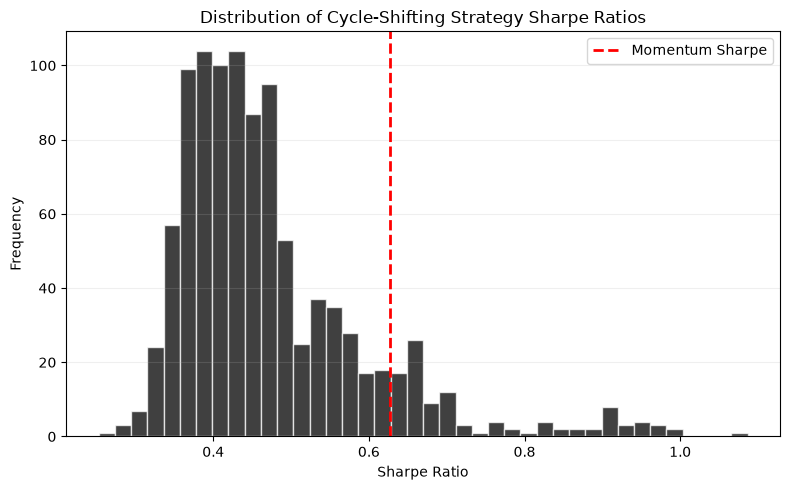

In [24]:
summary(simulation_df, momentum_results, "Distribution of Cycle-Shifting Strategy Sharpe Ratios")